<table>
    <tr>
        <td style="text-align:left">
            <img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcR9ItLTT_F-3Q30cu7ZCCoKmuFGBt22pe7pNA" alt="Logo Universidad" width="300"/>
        </td>
        <td>
            Departamento de Ciencias de la Computación y de la Decisión<br>
            Facultad de Minas<br>
            Universidad Nacional de Colombia<br>
            Optimizacion e IA 2026-2S<br><br>
            Docente: Maria Constanza Torres Madronero<br>
            <br>
            Contribuciones a la guia por: <br>
            - Deimer Miranda Montoya (2023)<br>
            - Luis Fernando Becerra Monsalve (2024)
        </td>    
        </td>    
    </tr>
</table>

# Clustering
Una tarea frecuente en aprendizaje de máquinas no supervisado es el agrupamiento o clustering. Estas técnicas permiten descubrir relaciones o patrones ocultos en los datos analizados. Existen diferentes métodos de agrupamiento, destacándose Kmeans por su simplicidad. En esta práctica compararemos Kmeans con técnicas de clustering que emplean métodos metaheuristicos como GA.

Primero generaremos una nube de datos para comparar los diferentes algoritmos. Para esto usaremos nuevamente herramientas disponibles en la librería sklearn.

In [1]:
#Importar librerias
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

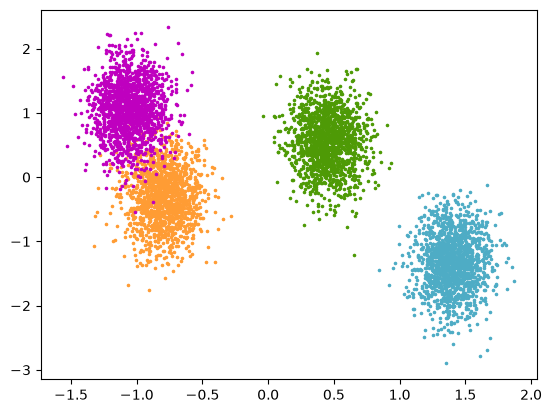

In [4]:
#Generacion de nubes de puntos
K = 4
D = 2
N = 6000
#Ejemplo 1: 4 clusters - 2 dimensiones - random_state=37
X, y_true = make_blobs(n_samples=N, centers=K, n_features=D, random_state=37)
#Importante: normalizar los datos
scaler = StandardScaler()
X = scaler.fit_transform(X)
#Visualizacion de los datos
colors = ["#4EACC5", "#FF9C34", "#4E9A06", 'm']
for k, col in enumerate(colors):
    cluster_data = y_true == k
    plt.scatter(X[cluster_data, 0], X[cluster_data, 1], c=col, marker=".", s=10)

# Kmeans
Para esta práctica usaremos la implementación clásica de Kmeans empleando el método disponible en la librería sklearn.

In [6]:
#Configuracion del modelo
#Se define el numero de clusters, la inicialización y las veces que se repite el proceso
kmeans = KMeans(n_clusters=K, init="random", n_init=10, random_state=10) # numero de iteraciones 300 por defecto

#Entrenamiento
kmeans.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",4
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'random'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",10
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](4, 2)","[[ 1.4 ,

# Coeficiente de silueta

Vamos a usar el [coeficiente de silueta](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html) como métrica de desempeño de los algoritmos de clustering. Existen diferentes métricas para esto, como la suma de la distancia al cuadrado de cada punto a su centroide. Sin embargo, el coeficiente de silueta no solo tiene en cuenta la distancia intra-cluster (distancia de cada punto al centro del clúster: a), sino también la distancia al clúster más cercano (b). El coeficiente de silueta para una muestra está dado por (b - a) / max(a, b). El mejor valor que se puede obtener es 1 y el peor -1. Valores cercanos a 0 indican clústeres que se sobreponen. Valores negativos indican una mala asignación de muestras a los clústeres, dado que existe un clúster más cercano o simular a ciertas muestras.

In [7]:
#Calculo del coeficiente de silueta
score = silhouette_score(X, kmeans.labels_)
print("Coeff Silueta para Kmeans: = ", score)

Coeff Silueta para Kmeans: =  0.652066121740679


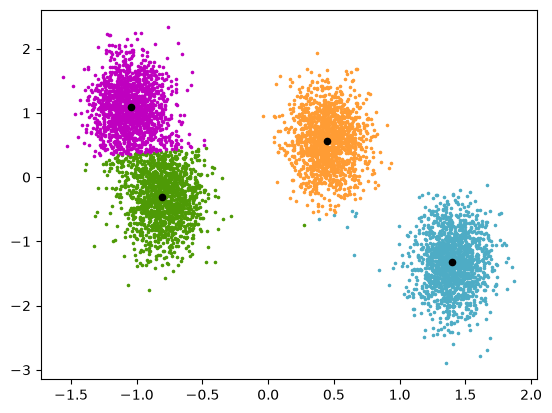

In [8]:
#Grafica de los cluster y centroides obtenidos
for k, col in enumerate(colors):
    filtered = X[kmeans.labels_==k]
    plt.scatter(filtered[:, 0], filtered[:, 1], c=col, marker=".", s=10)
    plt.scatter(kmeans.cluster_centers_[k, 0], kmeans.cluster_centers_[k, 1], c="black", marker="o", s=20)
    

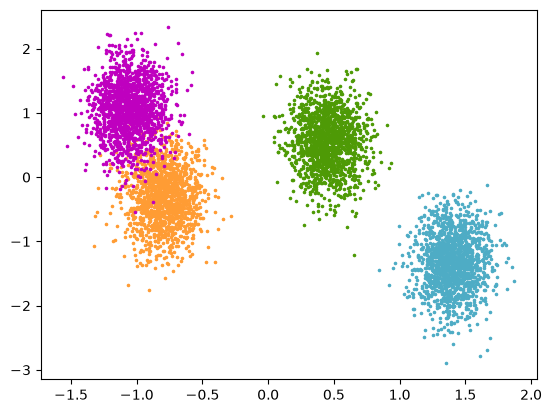

In [9]:
colors = ["#4EACC5", "#FF9C34", "#4E9A06", 'm']
for k, col in enumerate(colors):
    cluster_data = y_true == k
    plt.scatter(X[cluster_data, 0], X[cluster_data, 1], c=col, marker=".", s=10)

 Se ve que no hay superposición entre los clusters, sino que se divide el morado y verde por una linea casi recta

# Algoritmo Genético
Vamos a usar la libreria PyGAD para realizar el proceso de clustering.

In [ ]:
#Instalacion de la libreria
#Requiere ser instalada en el entorno de ejecución
#!pip install pygad

In [10]:
#Importar libreria pygad
import pygad

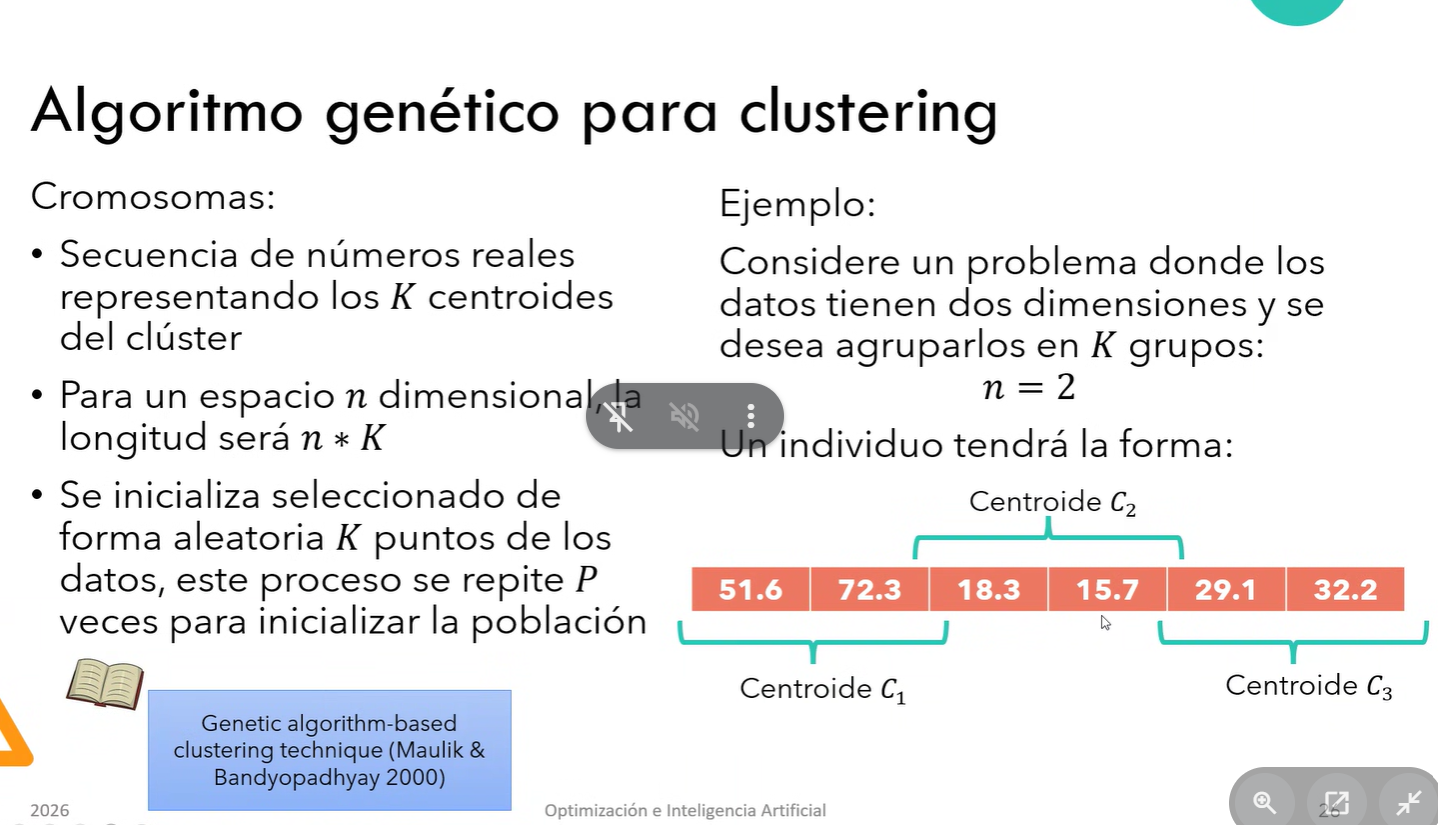

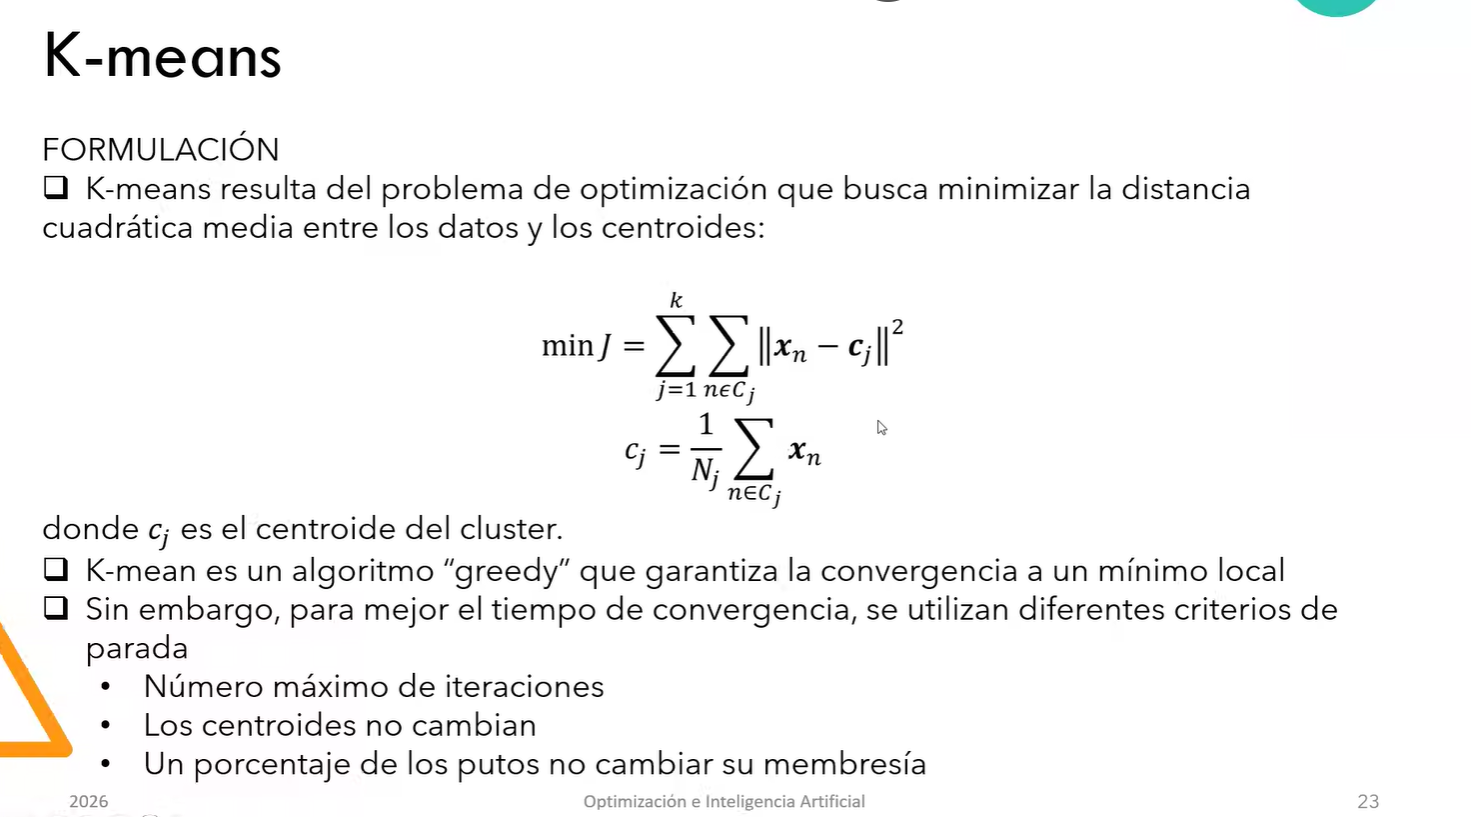

In [11]:
#Paso 1: Definire funcion fitness (funcion de aptitud)
#solution: arreglo con los centroides del cluster
#solution = [c1(x) c1(x) c2(x) c2(y)... cn(x) cn(y)]

def fitness_func(ga_instance, solution, solution_idx):
    """
    Evalúa la calidad de los centroides propuestos por el cromosoma.
    Calcula la suma de los errores al cuadrado (SSE) e invierte el valor,
    ya que PyGAD maximiza la función de fitness.
    """
    # Reestructurar el vector plano del cromosoma a una matriz (K, D) de centroides
    centroides = np.reshape(solution, (K, D))

    # Calcular la distancia euclidiana de cada punto de X a cada uno de los K centroides
    # Matriz resultante de dimensiones: (n_samples, K)
    distancias = np.linalg.norm(X[:, np.newaxis, :] - centroides, axis=2)

    # Asignar cada punto al centroide más cercano
    distancias_minimas = np.min(distancias, axis=1)

    # Suma de Errores Cuadráticos (Inercia / SSE)
    sse = np.sum(distancias_minimas ** 2)

    # Evitar división por cero y transformar en un problema de maximización
    # Un SSE más bajo producirá un valor de fitness más alto.
    fitness = 1.0 / (sse + 1e-6)
    return fitness

Genes = K (clusters) * D (Dimensiones)

In [12]:
#Paso 2: Preparamos los parametros para correr el algoritmo genetico
#Instanciar el Algoritmo
ga_instance = pygad.GA(num_generations=100,
                       num_parents_mating=10,
                       fitness_func=fitness_func,
                       sol_per_pop=20,
                       num_genes=K*D, #Numero de genes en la solucion, posisiocnes en el arreglo
                       init_range_low=np.min(X),
                       init_range_high=np.max(X),
                       parent_selection_type="rws",
                       keep_parents=5,
                       crossover_type="single_point",
                       crossover_probability = 0.8,
                       mutation_type="random",
                       mutation_probability=0.1
                       )


c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\pygad\utils\validation.py:459: UserWarning: keep_elitism (=1) takes precedence over keep_parents (=5). Set keep_elitism=0 to retain parents instead.
  warnings.warn(f'keep_elitism (={self.keep_elitism}) takes precedence over keep_parents (={self.keep_parents}). Set keep_elitism=0 to retain parents instead.')


In [13]:
#Corremos el algoritmo
ga_instance.run()

In [14]:
#Extraemos la mejor solucion
solution, solution_fitness, solution_idx = ga_instance.best_solution()
print(f"Parameters of the best solution : {solution}")
print(f"Fitness value of the best solution = {solution_fitness}")


Parameters of the best solution : [-0.71346407 -0.35868382  1.37583478 -1.34731205  0.45448111  0.55320004
 -1.12556276  1.12008464]
Fitness value of the best solution = 0.0008676550643883052


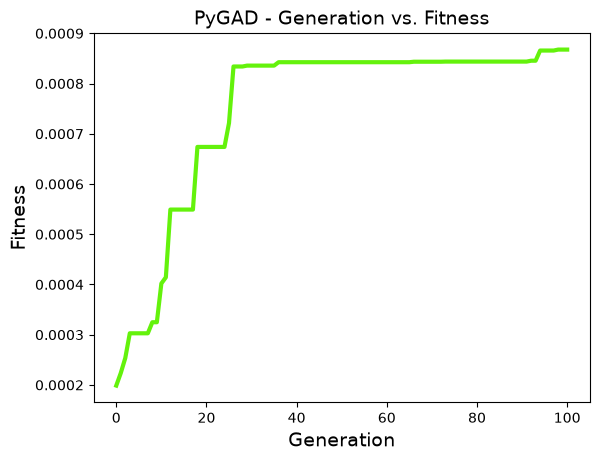

In [18]:
#Graficamos la funcion Fitness
fig = ga_instance.plot_fitness()

In [ ]:
#Extraemos los centroides optimos
centroides_optimos = np.reshape(solution, (K, D))
#Calculamos las distancias finales
distancias_finales = np.linalg.norm(X[:, np.newaxis, :] - centroides_optimos, axis=2) #distancias al cuadrado y nos quedamos con la mínima
#Agrupamos
GA_labels = np.argmin(distancias_finales, axis=1)

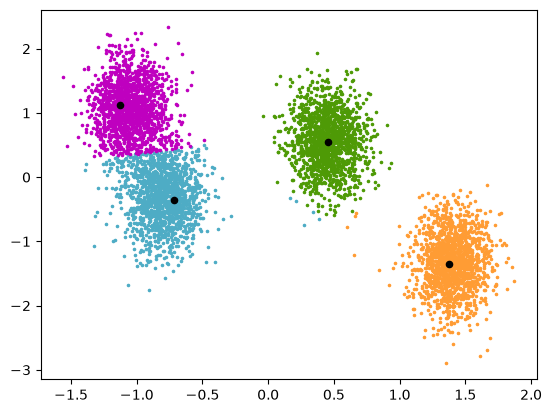

In [17]:
#Mostrar clusters
i=0
for k, col in enumerate(colors):
    filtered = X[GA_labels==k]
    plt.scatter(filtered[:, 0], filtered[:, 1], c=col, marker=".", s=10)
    plt.scatter(solution[i], solution[i+1], c="black", marker="o", s=20)
    i+=2

In [19]:
#Calculo del coeficiente de silueta
score = silhouette_score(X, GA_labels)
print("Coeff Silueta para Kmeans: = ", score)

Coeff Silueta para Kmeans: =  0.6518706441980636


Mejoras:

otras distancias: `` no np.linalg.norm(X[:, np.newaxis, :] - centroides, axis=2)``

no la distancia euclidiana es mejor coseno si son mucho datos

texto: especializadas para docmentos 

